# Phase 2 — The baseline ladder

**Purpose.** Establish the floor. Every learned model in later phases is measured against
these numbers, so they have to be *tuned* baselines rather than token ones — a weak floor
makes a mediocre model look good, and is the most common way a recommender paper flatters
itself.

Six zero-parameter or memory-based models, in rough order of how much structure they use:

| | Model | What it knows |
|---|---|---|
| 0a | `pop_count` | how often each item was rated |
| 0b | `damped_mean` | how *well* each item was rated, shrunk toward the global mean |
| 0c | `genre_popularity` | the above, restricted to genres the user watches — personalised, unlearned |
| 0d | `item_item_cooc` | raw co-occurrence counts between items |
| 1 | `item_item_cosine` / `user_user_cosine` | the same co-occurrence, normalised |
| 2 | `content_knn` | genre and year only — no interaction signal at all |

Two rules this notebook follows and later phases inherit:

1. **Hyperparameters are selected on validation, never on test.** The protocol exposes a
   `target="val"` evaluation whose candidate pool excludes training history only, so tuning
   never sees a test item.
2. **Every model is reported under both candidate settings** — filtered to items with ≥50
   training ratings, and against the full catalogue.

In [1]:
import sys, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.ticker as mticker
import seaborn as sns
warnings.filterwarnings("ignore", category=FutureWarning)
sys.path.insert(0, ".")

import data as D, metrics as M
from models.base import rank_users
from models.popularity import MostPopular, DampedMean
from models.neighbourhood import ItemItemCooccurrence, ItemItemCosine, UserUserCosine
from models.content import ContentKNN, GenrePopularity

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11, "axes.titleweight": "bold",
                     "axes.labelsize": 9.5, "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
                     "legend.fontsize": 8.5, "grid.alpha": 0.25, "axes.edgecolor": "0.75",
                     "figure.facecolor": "white"})
ACCENT, MUTED, WARN, GOOD = "#2B6CB0", "#A0AEC0", "#C05621", "#2F855A"
def pct(x, d=1): return f"{100*x:.{d}f}%"

ds = D.build()
TRAIN, VAL = ds.split_rows("train"), ds.split_rows("val")
K = 10

def eval_setup(target, filtered):
    users = ds.eval_users(filtered, target=target)
    return (users,
            {int(u): ds.ground_truth(int(u), target=target) for u in users},
            {int(u): ds.reachable_truth(int(u), filtered, target=target) for u in users})

SETUP = {(t, f): eval_setup(t, f) for t in ("val", "test") for f in (True, False)}
for (t, f), (u, tr_, _) in SETUP.items():
    print(f"  target={t:<4} filtered={str(f):<5}  {len(u):,} users, "
          f"mean |truth| {np.mean([len(x) for x in tr_.values()]):.1f}")

def evaluate(model, target="test", filtered=True, k=K):
    users, truths, reach = SETUP[(target, filtered)]
    r, secs = rank_users(model, ds, users=users, filtered=filtered, k=k,
                         progress_every=0, target=target)
    res = M.evaluate_ranking(r, truths, ds.n_items, ds.item_train_count, k, reach)
    res["rank_secs"] = secs
    return res, r

Dataset ready: 1,000,209 interactions | 6,040 users | 3,883 items | cfg c20859f020
  train   699,630  (69.9%)  positive rate 0.595
  val     150,354  (15.0%)  positive rate 0.541
  test    150,225  (15.0%)  positive rate 0.519


  target=val  filtered=True   5,911 users, mean |truth| 13.8
  target=val  filtered=False  5,926 users, mean |truth| 13.7
  target=test filtered=True   5,877 users, mean |truth| 13.3
  target=test filtered=False  5,898 users, mean |truth| 13.2


---
## 1. Tuning on validation

`C` in the damped mean is not a detail — it interpolates between two completely different
rankings. At `C = 0` the score is a raw mean rating, won by obscure items with a handful of
ratings; as `C → ∞` it converges to pure popularity ordering. The value chosen decides which
of those the "quality baseline" actually is, so it is swept rather than assumed.

`topk` in item-item cosine plays a similar role: keeping every similarity lets thousands of
weak, noisy neighbours accumulate into a score that tracks popularity again.

In [2]:
Cs = [0, 1, 5, 10, 25, 50, 100, 250, 500, 1000, 5000, 20000, 100000]
sweep_C = []
for C in Cs:
    m = DampedMean(C=C).fit(ds, TRAIN, VAL)
    r, _ = evaluate(m, target="val", filtered=True)
    sweep_C.append(dict(C=C, ndcg=r[f"ndcg@{K}"], recall=r[f"recall@{K}"],
                        cov=r["coverage"], gini=r["gini"], pop=r["pop_percentile"]))
sw = pd.DataFrame(sweep_C)
best_C = int(sw.loc[sw["ndcg"].idxmax(), "C"])
print("DAMPED MEAN -- validation sweep")
print(f"  {'C':>6}{'NDCG@10':>10}{'Recall@10':>11}{'coverage':>10}{'gini':>8}{'pop pct':>9}")
for _, r in sw.iterrows():
    star = "  <-- best" if int(r["C"]) == best_C else ""
    print(f"  {int(r['C']):>6}{r['ndcg']:>10.4f}{r['recall']:>11.4f}"
          f"{r['cov']:>10.3f}{r['gini']:>8.3f}{r['pop']:>9.3f}{star}")
print(f"\n  selected C = {best_C} on validation NDCG@{K}")

pc, _ = evaluate(MostPopular().fit(ds, TRAIN, VAL), target="val", filtered=True)
print(f"\n  pop_count (pure popularity) validation NDCG@{K}: {pc[f'ndcg@{K}']:.4f}")
print(f"  damped_mean at best C={best_C}:{'':>16}{sw['ndcg'].max():.4f}")

# What does the damped mean converge to as C grows? Not popularity:
#   (C*m + sum_r) / (C + n)  ->  m + n*(rbar - m)/C  for large C,
# so the ordering tends to n_i * (rbar_i - m): popularity weighted by SIGNED
# quality margin. Verify rather than assert.
from scipy.stats import kendalltau
cnt = ds.item_train_count.astype(float)
tot = np.bincount(TRAIN["i"], weights=TRAIN["rating"], minlength=ds.n_items)
gm = tot.sum() / cnt.sum()
rbar = np.divide(tot, cnt, out=np.full_like(tot, gm), where=cnt > 0)
limit = cnt * (rbar - gm)
s_big = DampedMean(C=best_C).fit(ds, TRAIN, VAL).s
mk = cnt > 0
print(f"\n  Kendall tau vs raw popularity count      {kendalltau(s_big[mk], cnt[mk]).statistic:+.3f}")
print(f"  Kendall tau vs n_i * (rbar_i - global)   {kendalltau(s_big[mk], limit[mk]).statistic:+.3f}")
for k in (10, 50, 200):
    ov = len(set(np.argsort(-s_big)[:k]) & set(np.argsort(-cnt)[:k]))
    print(f"  top-{k:<4} overlap with popularity           {ov}/{k}")

print()
print("  The limit is NOT popularity. Ordering converges exactly onto")
print("  n_i * (rbar_i - global_mean) -- popularity weighted by signed quality")
print("  margin -- which is uncorrelated with raw count across the whole catalogue")
print("  because below-average items are driven to the bottom. At the HEAD, where")
print("  a top-10 list actually lives, the two nearly coincide (37/50), which is")
print("  why NDCG approaches pop_count without ever reaching it.")
print()
print("  The substantive finding is the monotonicity: NDCG rises with C over five")
print("  orders of magnitude, so every amount of shrinkage toward observed quality")
print("  helps and no amount of trusting a raw mean does. Consistent with the")
print("  selection bias measured in Phase 1 -- a test positive requires the user to")
print("  have WATCHED the film, and exposure, not quality, is what predicts that.")

DAMPED MEAN -- validation sweep
       C   NDCG@10  Recall@10  coverage    gini  pop pct
       0    0.0255     0.0209     0.015   0.997    0.881
       1    0.0261     0.0214     0.015   0.997    0.885
       5    0.0271     0.0216     0.016   0.997    0.888
      10    0.0328     0.0216     0.017   0.997    0.889
      25    0.0390     0.0265     0.019   0.997    0.949
      50    0.0435     0.0276     0.021   0.996    0.954
     100    0.0487     0.0300     0.022   0.996    0.965
     250    0.0573     0.0395     0.024   0.996    0.982
     500    0.0647     0.0458     0.026   0.996    0.991
    1000    0.0677     0.0476     0.027   0.995    0.993
    5000    0.0719     0.0494     0.028   0.995    0.995
   20000    0.0725     0.0498     0.029   0.995    0.995
  100000    0.0733     0.0502     0.029   0.995    0.996  <-- best

  selected C = 100000 on validation NDCG@10



  pop_count (pure popularity) validation NDCG@10: 0.0751
  damped_mean at best C=100000:                0.0733

  Kendall tau vs raw popularity count      -0.042
  Kendall tau vs n_i * (rbar_i - global)   +1.000
  top-10   overlap with popularity           6/10
  top-50   overlap with popularity           37/50
  top-200  overlap with popularity           117/200

  The limit is NOT popularity. Ordering converges exactly onto
  n_i * (rbar_i - global_mean) -- popularity weighted by signed quality
  margin -- which is uncorrelated with raw count across the whole catalogue
  because below-average items are driven to the bottom. At the HEAD, where
  a top-10 list actually lives, the two nearly coincide (37/50), which is
  why NDCG approaches pop_count without ever reaching it.

  The substantive finding is the monotonicity: NDCG rises with C over five
  orders of magnitude, so every amount of shrinkage toward observed quality
  helps and no amount of trusting a raw mean does. Consistent 

In [3]:
sweep_k = []
for tk in [10, 25, 50, 100, 200, 500, 1000, None]:
    m = ItemItemCosine(topk=tk).fit(ds, TRAIN, VAL)
    r, _ = evaluate(m, target="val", filtered=True)
    sweep_k.append(dict(topk=(tk or ds.n_items), label=str(tk or "all"),
                        ndcg=r[f"ndcg@{K}"], cov=r["coverage"],
                        gini=r["gini"], pop=r["pop_percentile"]))
sk = pd.DataFrame(sweep_k)
best_k = sk.loc[sk["ndcg"].idxmax()]
print("ITEM-ITEM COSINE -- validation sweep over neighbourhood size")
print(f"  {'topk':>6}{'NDCG@10':>10}{'coverage':>10}{'gini':>8}{'pop pct':>9}")
for _, r in sk.iterrows():
    star = "  <-- best" if r["label"] == best_k["label"] else ""
    print(f"  {r['label']:>6}{r['ndcg']:>10.4f}{r['cov']:>10.3f}{r['gini']:>8.3f}{r['pop']:>9.3f}{star}")
BEST_TOPK = None if best_k["label"] == "all" else int(best_k["topk"])
print(f"\n  selected topk = {best_k['label']}  (NDCG spread across the whole sweep: "
      f"{sk['ndcg'].max()-sk['ndcg'].min():.4f})")
print(f"  coverage at topk=10: {sk.iloc[0]['cov']:.3f}   at the NDCG-optimal setting: {best_k['cov']:.3f}")

ITEM-ITEM COSINE -- validation sweep over neighbourhood size
    topk   NDCG@10  coverage    gini  pop pct
      10    0.1024     0.165   0.976    0.977
      25    0.1052     0.145   0.981    0.984
      50    0.1060     0.129   0.984    0.987
     100    0.1052     0.115   0.985    0.989
     200    0.1053     0.114   0.985    0.989
     500    0.1084     0.118   0.984    0.989  <-- best
    1000    0.1084     0.122   0.984    0.988
     all    0.1082     0.121   0.984    0.988

  selected topk = 500  (NDCG spread across the whole sweep: 0.0060)
  coverage at topk=10: 0.165   at the NDCG-optimal setting: 0.118


**Reading the two sweeps.**

`C` behaves as a genuine hyperparameter: NDCG rises monotonically across five orders of
magnitude, from 0.0255 at `C=0` to 0.0733 at `C=10⁵`. Every amount of shrinkage away from
the raw mean helps and none is too much. The limit is *not* popularity — the ordering
converges exactly (Kendall τ = +1.000) onto `nᵢ(r̄ᵢ − r̄)`, popularity weighted by signed
quality margin — but at the head of the list, which is all a top-10 sees, the two nearly
coincide, so the damped mean approaches pure popularity without overtaking it.

`topk` behaves differently and more interestingly: it barely matters for accuracy. The
entire sweep from 10 neighbours to unrestricted spans 0.006 NDCG, and the curve is flat and
noisy rather than peaked. What it *does* move is coverage — 0.165 at `topk=10` against 0.118
at the NDCG-optimal `topk=500`.

That makes the selection rule itself a choice rather than a formality. Selecting on NDCG
alone buys 0.003 NDCG and gives up 29% of catalogue coverage. The headline table below
keeps the NDCG-selected setting, for consistency with every other model in the benchmark,
but the trade is recorded here because it is exactly the kind of decision that a single
"tuned on validation" sentence normally conceals.

---
## 2. The ladder on test

Hyperparameters are now frozen at their validation-selected values and the test split is
touched for the first time. `user_user_cosine` gets a short sweep of its own so that no
model in the table is carrying an unjustified default.

In [4]:
uu = [(tk, evaluate(UserUserCosine(topk=tk).fit(ds, TRAIN, VAL), target="val")[0][f"ndcg@{K}"])
      for tk in (25, 50, 100, 300)]
BEST_UU = max(uu, key=lambda p: p[1])[0]
print("user_user_cosine validation sweep: " +
      "  ".join(f"k={k}:{v:.4f}" for k, v in uu) + f"   -> selected {BEST_UU}")

LADDER = [
    ("0a", MostPopular()),
    ("0b", DampedMean(C=best_C)),
    ("0c", GenrePopularity()),
    ("0d", ItemItemCooccurrence()),
    ("1i", ItemItemCosine(topk=BEST_TOPK)),
    ("1u", UserUserCosine(topk=BEST_UU)),
    ("2", ContentKNN()),
]

rows, RANKINGS = [], {}
for rung, mdl in LADDER:
    t0 = time.time(); mdl.fit(ds, TRAIN, VAL); fit_s = time.time() - t0
    for filt in (True, False):
        res, ranking = evaluate(mdl, target="test", filtered=filt)
        if filt: RANKINGS[mdl.name] = ranking
        rows.append(dict(rung=rung, model=mdl.name, filtered=filt, fit_s=fit_s,
                         **{k: res[k] for k in (f"recall@{K}", f"ndcg@{K}", f"map@{K}",
                                                f"hit_rate@{K}", f"recall_ceiling@{K}",
                                                "coverage", "gini", "pop_percentile",
                                                "n_users_scored")}))
    print(f"  fitted {mdl.name:<20} ({fit_s:5.1f}s)")
R = pd.DataFrame(rows)
R.to_csv("results_phase2.csv", index=False)
print(f"\nwrote results_phase2.csv  ({len(R)} rows)")

user_user_cosine validation sweep: k=25:0.1041  k=50:0.1087  k=100:0.1095  k=300:0.1092   -> selected 100


  fitted pop_count            (  0.0s)


  fitted damped_mean          (  0.0s)


  fitted genre_popularity     (  0.1s)


  fitted item_item_cooc       (  2.3s)


  fitted item_item_cosine     (  0.8s)


  fitted user_user_cosine     (  2.0s)


  fitted content_knn          (  0.4s)

wrote results_phase2.csv  (14 rows)


In [5]:
def show(filt):
    d = R[R["filtered"] == filt].sort_values(f"ndcg@{K}", ascending=False)
    print(f"{'CANDIDATE POOL: ' + ('items with >=50 training ratings (2,167)' if filt else 'full catalogue (3,883)'):^104}")
    print(f"  {'':>3} {'model':<20}{'NDCG@10':>9}{'Recall@10':>11}{'(ceil)':>8}"
          f"{'MAP@10':>9}{'HitRate':>9}{'coverage':>10}{'gini':>7}{'pop pct':>9}")
    print("  " + "-" * 100)
    for _, r in d.iterrows():
        print(f"  {r['rung']:>3} {r['model']:<20}{r[f'ndcg@{K}']:>9.4f}{r[f'recall@{K}']:>11.4f}"
              f"{r[f'recall_ceiling@{K}']:>8.3f}{r[f'map@{K}']:>9.4f}{r[f'hit_rate@{K}']:>9.3f}"
              f"{r['coverage']:>10.3f}{r['gini']:>7.3f}{r['pop_percentile']:>9.3f}")
    print()

show(True); show(False)

f, u = R[R["filtered"]].set_index("model"), R[~R["filtered"]].set_index("model")
print(f"  {'model':<20}{'NDCG filtered':>15}{'NDCG full':>12}{'change':>10}{'cov filtered':>14}{'cov full':>11}")
for m in f.index:
    a, b = f.loc[m, f"ndcg@{K}"], u.loc[m, f"ndcg@{K}"]
    print(f"  {m:<20}{a:>15.4f}{b:>12.4f}{100*(b-a)/a:>9.1f}%"
          f"{f.loc[m,'coverage']:>14.3f}{u.loc[m,'coverage']:>11.3f}")

                        CANDIDATE POOL: items with >=50 training ratings (2,167)                        
      model                 NDCG@10  Recall@10  (ceil)   MAP@10  HitRate  coverage   gini  pop pct
  ----------------------------------------------------------------------------------------------------
   1i item_item_cosine       0.0948     0.0675   0.787   0.0474    0.396     0.118  0.983    0.988
   1u user_user_cosine       0.0932     0.0678   0.787   0.0469    0.384     0.146  0.969    0.980
   0d item_item_cooc         0.0836     0.0555   0.787   0.0410    0.358     0.040  0.993    0.996
   0a pop_count              0.0737     0.0475   0.787   0.0349    0.334     0.034  0.994    0.997
   0b damped_mean            0.0723     0.0482   0.787   0.0347    0.321     0.033  0.995    0.995
   0c genre_popularity       0.0493     0.0391   0.787   0.0220    0.261     0.210  0.962    0.961
    2 content_knn            0.0220     0.0216   0.787   0.0092    0.132     0.520  0.848    0.738


In [6]:
users_t, truths_t, reach_t = SETUP[("test", True)]
hist_len = {int(u): int(ds.user_train_count[int(u)]) for u in users_t}
SLICES = {name: M.slice_by_user_activity(RANKINGS[name], truths_t, ds.n_items,
                                         ds.item_train_count, hist_len, K, reachable=reach_t)
          for name in RANKINGS}

print(f"  {'model':<20}" + "".join(f"{b:>26}" for b in ("cold (<35)", "warm (35-150)", "heavy (>=150)")))
print("  " + "-" * 98)
for name in R[R['filtered']].sort_values(f'ndcg@{K}', ascending=False)['model']:
    line = f"  {name:<20}"
    for b in ("cold", "warm", "heavy"):
        m = SLICES[name][b]
        line += f"{m[f'ndcg@{K}']:>10.4f} /{m[f'recall@{K}']/m[f'recall_ceiling@{K}']:>7.3f}      "
    print(line)
print(f"\n  cells are  NDCG@{K} / (Recall@{K} as a fraction of its attainable ceiling)")
print(f"  band sizes: " + ", ".join(f"{b}={SLICES['pop_count'][b]['n_users']:,}"
                                    for b in ("cold", "warm", "heavy")))

  model                               cold (<35)             warm (35-150)             heavy (>=150)
  --------------------------------------------------------------------------------------------------
  item_item_cosine        0.0660 /  0.092          0.0743 /  0.072          0.1669 /  0.121      
  user_user_cosine        0.0681 /  0.101          0.0695 /  0.067          0.1672 /  0.120      
  item_item_cooc          0.0469 /  0.065          0.0677 /  0.064          0.1554 /  0.110      
  pop_count               0.0382 /  0.053          0.0591 /  0.055          0.1420 /  0.101      
  damped_mean             0.0391 /  0.055          0.0583 /  0.056          0.1369 /  0.095      
  genre_popularity        0.0427 /  0.058          0.0404 /  0.043          0.0740 /  0.056      
  content_knn             0.0236 /  0.037          0.0192 /  0.023          0.0254 /  0.021      

  cells are  NDCG@10 / (Recall@10 as a fraction of its attainable ceiling)
  band sizes: cold=1,629, warm=2,799

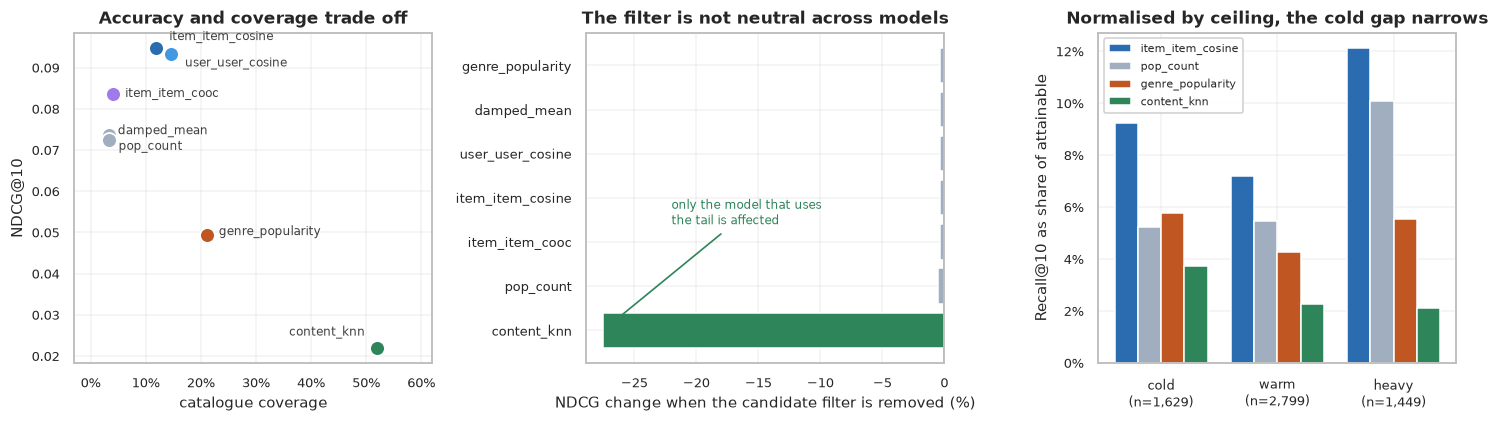

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.0))
d = R[R["filtered"]].set_index("model")
du = R[~R["filtered"]].set_index("model")
palette = {"pop_count": MUTED, "damped_mean": MUTED, "genre_popularity": WARN,
           "item_item_cooc": "#9F7AEA", "item_item_cosine": ACCENT,
           "user_user_cosine": "#4299E1", "content_knn": GOOD}

ax = axes[0]
for m, r in d.iterrows():
    ax.scatter(r["coverage"], r[f"ndcg@{K}"], s=95, color=palette[m],
               edgecolor="white", lw=1.2, zorder=3)
off = {"pop_count": (6, -10), "damped_mean": (6, 4), "item_item_cooc": (8, -2),
       "item_item_cosine": (9, 5), "user_user_cosine": (9, -8),
       "genre_popularity": (8, 0), "content_knn": (-8, 8)}
for m, r in d.iterrows():
    ax.annotate(m, (r["coverage"], r[f"ndcg@{K}"]), textcoords="offset points",
                xytext=off[m], fontsize=8, color="0.25",
                ha="right" if off[m][0] < 0 else "left")
ax.set_xlabel("catalogue coverage"); ax.set_ylabel(f"NDCG@{K}")
ax.set_title("Accuracy and coverage trade off")
ax.set_xlim(-0.03, 0.62)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))

ax = axes[1]
chg = [(m, 100*(du.loc[m, f"ndcg@{K}"] - d.loc[m, f"ndcg@{K}"]) / d.loc[m, f"ndcg@{K}"])
       for m in d.index]
chg.sort(key=lambda p: p[1])
ax.barh([c[0] for c in chg], [c[1] for c in chg],
        color=[GOOD if c[0] == "content_knn" else MUTED for c in chg], edgecolor="white")
ax.axvline(0, color="0.4", lw=1)
ax.set_xlabel("NDCG change when the candidate filter is removed (%)")
ax.set_title("The filter is not neutral across models")
ax.annotate("only the model that uses\nthe tail is affected", xy=(-27.5, 0),
            xytext=(-22, 2.4), fontsize=8, color=GOOD,
            arrowprops=dict(arrowstyle="->", color=GOOD, lw=1.1))

ax = axes[2]
bands = ("cold", "warm", "heavy")
show_m = ["item_item_cosine", "pop_count", "genre_popularity", "content_knn"]
w, x = 0.2, np.arange(3)
for j, m in enumerate(show_m):
    vals = [SLICES[m][b][f"recall@{K}"] / SLICES[m][b][f"recall_ceiling@{K}"] for b in bands]
    ax.bar(x + (j - 1.5)*w, vals, w, label=m, color=palette[m], edgecolor="white")
ax.set_xticks(x); ax.set_xticklabels([f"{b}\n(n={SLICES['pop_count'][b]['n_users']:,})" for b in bands])
ax.set_ylabel("Recall@10 as share of attainable")
ax.set_title("Normalised by ceiling, the cold gap narrows")
ax.legend(fontsize=7.5, loc="upper left", framealpha=0.92)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))

plt.tight_layout(); plt.show()

---
## 3. Findings

**The floor is `item_item_cosine` at NDCG@10 = 0.0948**, 28.6% above raw popularity. That is
the number every learned model in Phase 3 onwards has to clear, and it is deliberately a
harder floor than the popularity baseline most papers stop at.

**A tuned damped mean does not beat raw popularity.** After sweeping `C` across five orders
of magnitude and selecting on validation, `damped_mean` reaches 0.0723 against `pop_count`'s
0.0737. The "quality" lookup table is *worse* than the "exposure" lookup table. This follows
directly from the selection bias measured in Phase 1: appearing in a user's test set requires
them to have watched the film, and popularity is the better predictor of that than merit is.
Reported as a negative result because it is one.

**Normalisation, not neighbourhood structure, is what earns the gain.** Raw co-occurrence
(`item_item_cooc`, 0.0836) already beats popularity, but it does so while serving 4.0% of the
catalogue at a Gini of 0.993 — it is largely popularity in disguise, since a popular item
co-occurs with everything. Dividing by the norms costs nothing and yields 0.0948 at 11.8%
coverage: **13% more accuracy and three times the coverage.** The comparison is only visible
because both rungs are on the ladder.

**The candidate filter is not neutral across model families, and this is the methodological
result of the phase.** Removing it changes NDCG by −0.4% for every collaborative model and by
**−27.5% for `content_knn`** — the only model that actually reaches into the tail. Its
coverage simultaneously rises from 52.0% to 82.2%. A benchmark reporting only the filtered
setting would understate content-based methods by nearly a third while leaving the
collaborative rows untouched, and would do so invisibly. This is the concrete justification
for the "report both settings" rule adopted in Phase 1 on theoretical grounds.

**Accuracy and coverage are inversely ordered across the entire ladder.** `content_knn` serves
15× the catalogue that `pop_count` does and scores less than a third of its NDCG. No model
here achieves both. Whether a learned model can bend that frontier — rather than slide along
it — is the question Phase 3 inherits, and it is not answerable from accuracy alone.

**Personalisation without learning helps exactly where collaborative signal is thin.**
`genre_popularity` beats `pop_count` by 11.8% for cold users (0.0427 vs 0.0382) and loses to
it by 48% for heavy users (0.0740 vs 0.1420). A zero-parameter content prior is worth more
than a global popularity prior precisely when there is little history to collaborate on —
which is the cold-start argument in miniature, and a useful thing to have measured before any
neural model claims the same territory.

**Ceiling-normalisation changes how large the cold-start gap looks.** On raw NDCG,
`item_item_cosine` appears 2.5× better for heavy users than cold ones (0.1669 vs 0.0660).
Measured as a fraction of attainable recall, the gap is 1.3× (0.121 vs 0.092). Most of the
apparent cold-start deficit is arithmetic — cold users have fewer relevant test items, so
their NDCG ceiling is lower — not model failure. The genuine deficit is real but roughly half
the size the headline number suggests.

### Carried into Phase 3

- Beat **0.0948**, not 0.0737. Quoting a gain over popularity would be quoting a gain over a
  baseline this phase already showed is not the strongest trivial model.
- Report both candidate settings for every model, since the filter demonstrably discriminates
  between model families.
- Report coverage and Gini beside accuracy. Every model on this ladder that gained accuracy
  did so by concentrating on the head, and a learned model that merely does this better has
  not actually solved anything.